In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

df = pd.read_csv('../mini_project_1_DS02_05_26/dataset/credit_risk_dataset_transformed.csv')
print(df.shape)
df.head()

(31529, 20)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_grade_encoded,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,log_person_income,cred_hist_to_age
0,22,59000,123.0,35000,16.02,1,0.59,1,3,3,0,0,0,1,0,0,0,1,10.985310,0.130435
1,21,9600,5.0,1000,11.14,0,0.10,0,2,1,1,0,0,0,0,0,1,0,9.169623,0.090909
2,25,9600,1.0,5500,12.87,1,0.57,0,3,2,0,0,1,0,0,0,0,0,9.169623,0.115385
3,23,65500,4.0,35000,15.23,1,0.53,0,2,2,0,0,1,0,0,0,0,1,11.089821,0.083333
4,24,54400,8.0,35000,14.27,1,0.55,1,4,2,0,0,1,0,0,0,0,1,10.904138,0.160000


In [2]:
# Statystyki dla kolumn numerycznych (liczność, średnia, odchylenie, min, percentyle, max)
for col in ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income']:
    values = df[col].to_numpy()
    print(f"--- {col} ---")
    print(f"  średnia:   {np.mean(values):.4f}")
    print(f"  mediana:   {np.median(values):.4f}")
    print(f"  odch.std:  {np.std(values):.4f}")
    print(f"  min/max:   {np.min(values):.4f} / {np.max(values):.4f}")
    print(f"  percentyle 25/75: {np.percentile(values, 25):.4f} / {np.percentile(values, 75):.4f}")



--- person_age ---
  średnia:   27.7592
  mediana:   26.0000
  odch.std:  6.3660
  min/max:   20.0000 / 144.0000
  percentyle 25/75: 23.0000 / 30.0000
--- person_income ---
  średnia:   66704.4653
  mediana:   56000.0000
  odch.std:  62456.5675
  min/max:   4000.0000 / 6000000.0000
  percentyle 25/75: 39456.0000 / 80000.0000
--- person_emp_length ---
  średnia:   4.7905
  mediana:   4.0000
  odch.std:  4.1454
  min/max:   0.0000 / 123.0000
  percentyle 25/75: 2.0000 / 7.0000
--- loan_amnt ---
  średnia:   9665.1527
  mediana:   8000.0000
  odch.std:  6336.5614
  min/max:   500.0000 / 35000.0000
  percentyle 25/75: 5000.0000 / 12500.0000
--- loan_int_rate ---
  średnia:   11.0401
  mediana:   10.9900
  odch.std:  3.0717
  min/max:   5.4200 / 23.2200
  percentyle 25/75: 8.4900 / 13.1600
--- loan_percent_income ---
  średnia:   0.1697
  mediana:   0.1500
  odch.std:  0.1063
  min/max:   0.0000 / 0.8300
  percentyle 25/75: 0.0900 / 0.2300


In [3]:
# Usunięcie osób starszych niż 100 lat
df_clean = df[df["person_age"] <= 100].copy()

# Usunięcie stażu pracy powyżej 60 lat
df_clean = df_clean[df_clean["person_emp_length"] <= 60]

# Usunięcie danych, gdzie staż pracy a wiek (zakładając prace od 18 roku życia)
df_clean = df_clean[df_clean["person_emp_length"] <= (df_clean["person_age"] - 18)]

# Sprawdzenie, czy wartość kwoty kredytu oraz dochodów nie jest ujemna lub zerowa
df_clean = df_clean[df_clean["loan_amnt"] > 0]
df_clean = df_clean[df_clean["person_income"] > 0]

df_clean.info()

<class 'pandas.DataFrame'>
Index: 23742 entries, 2 to 31528
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   person_age                   23742 non-null  int64  
 1   person_income                23742 non-null  int64  
 2   person_emp_length            23742 non-null  float64
 3   loan_amnt                    23742 non-null  int64  
 4   loan_int_rate                23742 non-null  float64
 5   loan_status                  23742 non-null  int64  
 6   loan_percent_income          23742 non-null  float64
 7   cb_person_default_on_file    23742 non-null  int64  
 8   cb_person_cred_hist_length   23742 non-null  int64  
 9   loan_grade_encoded           23742 non-null  int64  
 10  loan_intent_EDUCATION        23742 non-null  int64  
 11  loan_intent_HOMEIMPROVEMENT  23742 non-null  int64  
 12  loan_intent_MEDICAL          23742 non-null  int64  
 13  loan_intent_PERSONAL         237

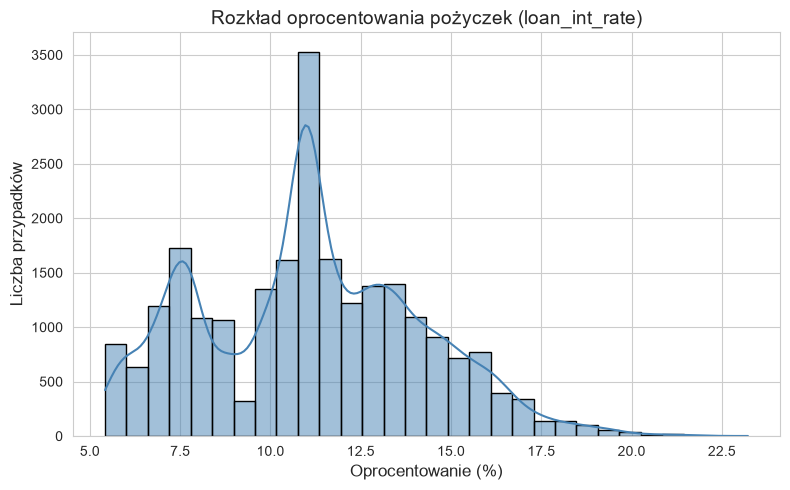

In [4]:
#Rozkład zmiennej loan_int_rate (Oprocentowanie kredytu)

plt.figure(figsize=(8, 5))
sns.histplot(
    df_clean["loan_int_rate"].dropna(),
    kde=True,
    bins=30,
    color="steelblue",
    edgecolor="black",
)
plt.title("Rozkład oprocentowania pożyczek (loan_int_rate)", fontsize=14)
plt.xlabel("Oprocentowanie (%)", fontsize=12)
plt.ylabel("Liczba przypadków", fontsize=12)
plt.tight_layout()
plt.show()

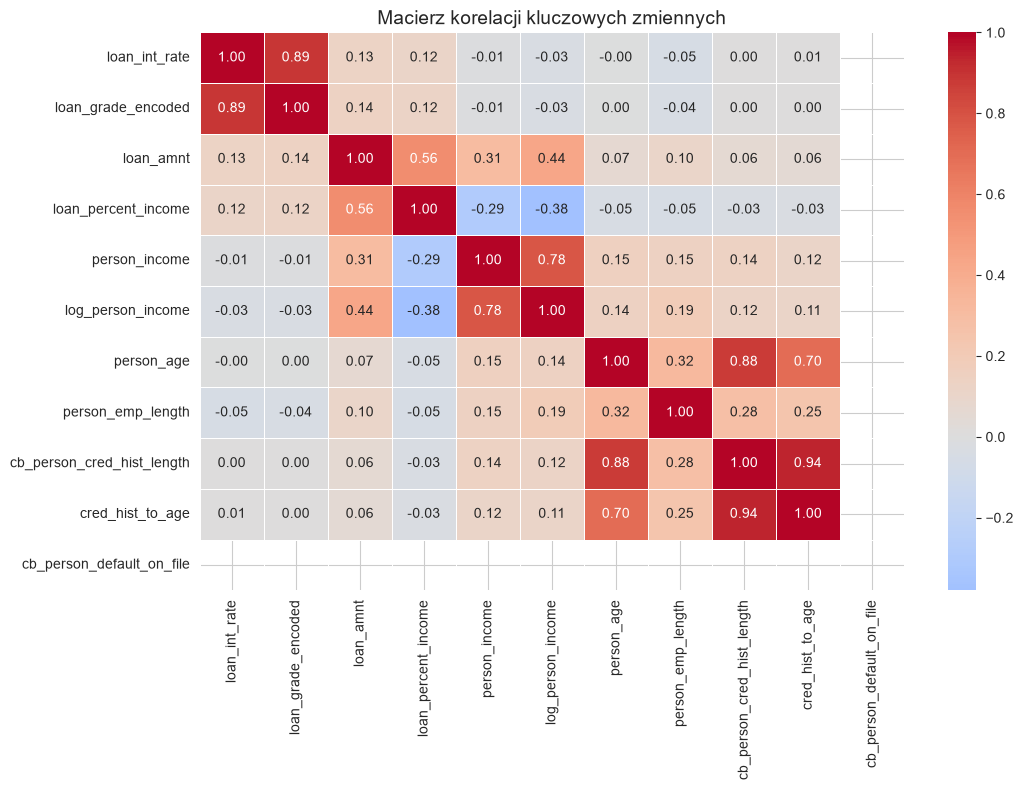

In [5]:
# Korelacje zmiennych numerycznych z targetem

df_clean['cb_person_default_on_file'] = df_clean['cb_person_default_on_file'].map({'N': 0, 'Y': 1})
 
num_cols = [
    'loan_int_rate', 'loan_grade_encoded', 'loan_amnt', 
    'loan_percent_income', 'person_income', 'log_person_income',
    'person_age', 'person_emp_length', 'cb_person_cred_hist_length', 
    'cred_hist_to_age', 'cb_person_default_on_file'
]

plt.figure(figsize=(11, 8))
corr_matrix = df_clean[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)

plt.title('Macierz korelacji kluczowych zmiennych', fontsize=14)
plt.tight_layout()
plt.show()



C:\Users\barbl\AppData\Local\Temp\ipykernel_2280\2560998363.py:12: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.violinplot(x='cb_person_default_on_file', y='loan_int_rate', data=df_clean, ax=ax2, hue='cb_person_default_on_file', palette='Set2', legend=False)


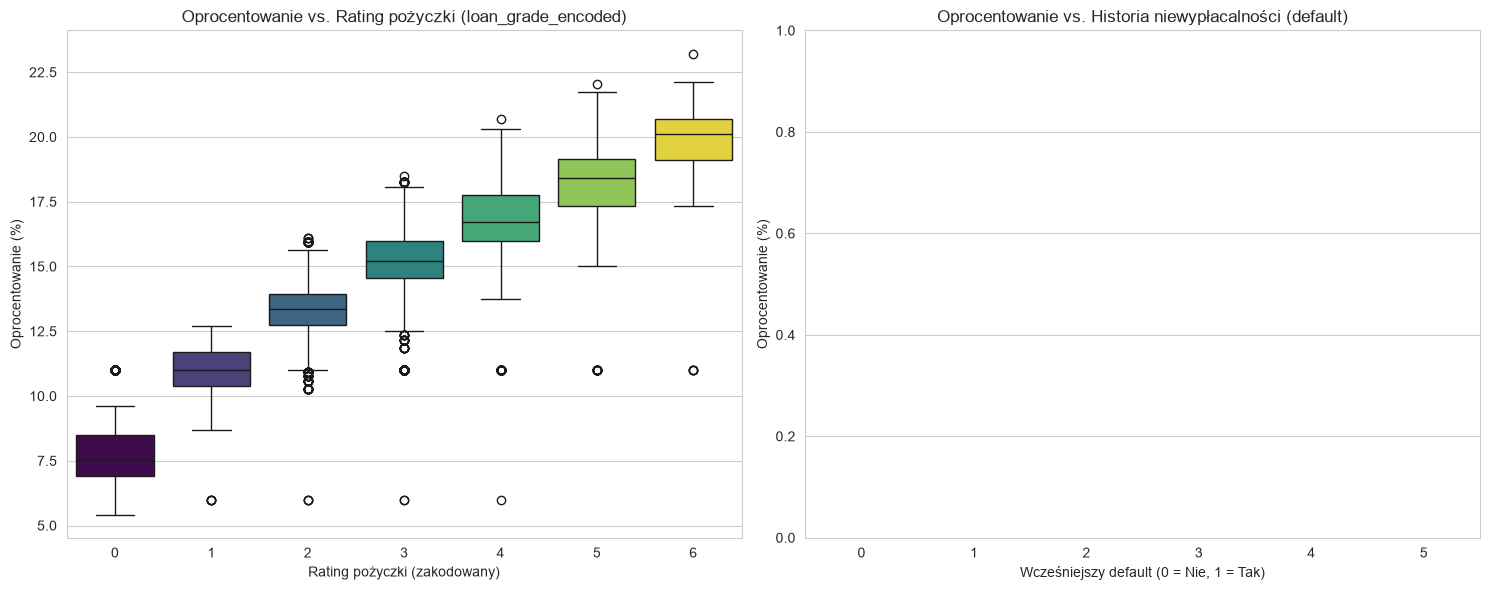

In [6]:
# Zależność Target vs. zmienne objaśniające

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Wykres A: Oprocentowanie vs Rating pożyczki
sns.boxplot(x='loan_grade_encoded', y='loan_int_rate', data=df_clean, ax=ax1, hue='loan_grade_encoded', palette='viridis', legend=False)
ax1.set_title('Oprocentowanie vs. Rating pożyczki (loan_grade_encoded)', fontsize=12)
ax1.set_xlabel('Rating pożyczki (zakodowany)')
ax1.set_ylabel('Oprocentowanie (%)')

# Wykres B: Oprocentowanie vs Historia niewypłacalności
sns.violinplot(x='cb_person_default_on_file', y='loan_int_rate', data=df_clean, ax=ax2, hue='cb_person_default_on_file', palette='Set2', legend=False)
ax2.set_title('Oprocentowanie vs. Historia niewypłacalności (default)', fontsize=12)
ax2.set_xlabel('Wcześniejszy default (0 = Nie, 1 = Tak)')
ax2.set_ylabel('Oprocentowanie (%)')

plt.tight_layout()
plt.show()

In [7]:
#Zapisujemy plik po transpormacji

df.to_csv("../mini_project_1_DS02_05_26/dataset/credit_risk_dataset_EDA.csv", index=False)

In [8]:
import os

print(os.path.exists("../mini_project_1_DS02_05_26/dataset/credit_risk_dataset_EDA.csv"))

True
